## Proprietary Models - Prompt Data & Base Model

In [1]:
# libraries
import os
from dotenv import load_dotenv
from huggingface_hub import login
from pricer.items import Item
from tqdm import tqdm
from transformers import AutoTokenizer
import matplotlib.pyplot as plt

In [ ]:
# logging in to the hugging face
# hf_token = userdata.get('HF_TOKEN')
# add_to_git_credential=True

hf_token = 'HF_TOKEN'
login(hf_token)

LITE_MODE = True

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [20]:
# uploading the dataset
username = 'ed-donner'
dataset = f"{username}/items_lite" if LITE_MODE else f"{username}/items_full"

train, val, test = Item.from_hub(dataset)
items = train + val + test

print(f"Loaded {len(train):,} training items, {len(val):,} validation items and {len(test):,} test items")

Loaded 20,000 training items, 1,000 validation items and 1,000 test items


In [22]:
# loading the base model 
BASE_MODEL = 'meta-llama/Llama-3.2-3B'

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

In [23]:
token_counts = [item.count_tokens(tokenizer) for item in tqdm(items)]

100%|██████████| 22000/22000 [00:02<00:00, 10852.35it/s]


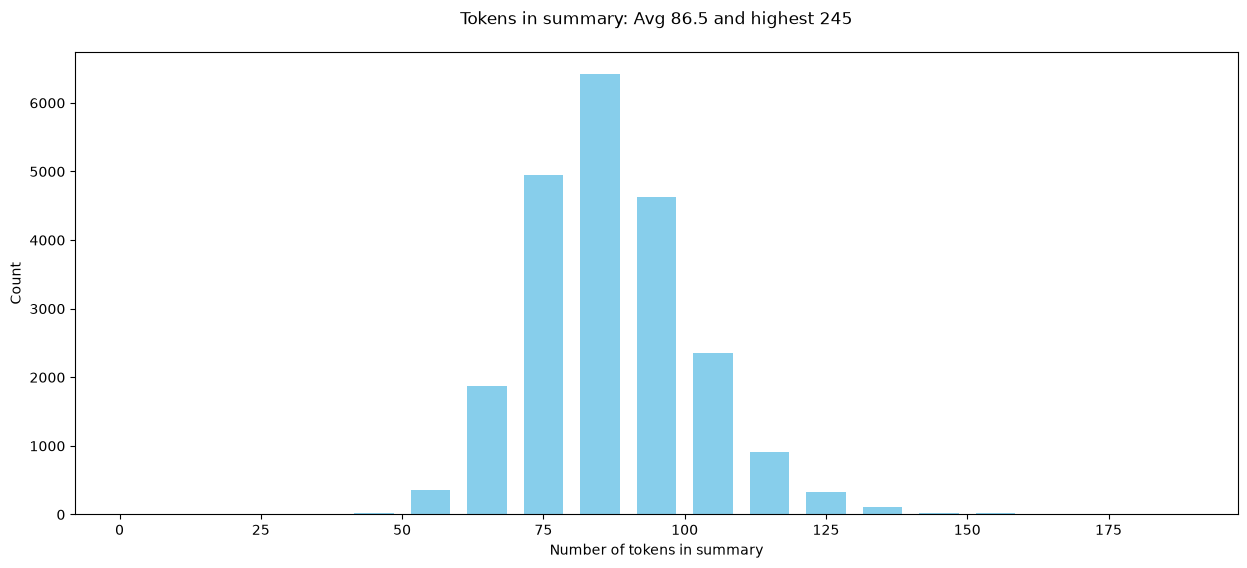

In [24]:
plt.figure(figsize=(15, 6))
plt.title(f"Tokens in summary: Avg {sum(token_counts)/len(token_counts):,.1f} and highest {max(token_counts):,}\n")
plt.xlabel("Number of tokens in summary")
plt.ylabel("Count")
plt.hist(token_counts, rwidth=0.7, color='skyblue', bins=range(0, 200, 10))
plt.show()

In [25]:
CUTOFF = 110
cut = len([count for count in token_counts if count > CUTOFF])
print(f"With this CUTOFF, we will truncate {cut:,} items, which is {cut/len(items):.1%}")

With this CUTOFF, we will truncate 1,255 items, which is 5.7%


In [26]:
for item in tqdm(train+val):
    item.make_prompts(tokenizer, CUTOFF, True)
for item in tqdm(test):
    item.make_prompts(tokenizer, CUTOFF, False)

100%|██████████| 1000/1000 [00:00<00:00, 11762.82it/s]


In [27]:
print("PROMPT:")
print(test[0].prompt)
print("COMPLETION:")
print(test[0].completion)

PROMPT:
What does this cost to the nearest dollar?

Title: Excess V2 Distortion/Modulation Pedal  
Category: Music Pedals  
Brand: Old Blood Noise  
Description: A versatile pedal offering distortion and three modulation modes—delay, chorus, and harmonized fifths—with full control over signal routing and expression.  
Details: Features include separate gain, tone, and volume controls; time, depth, and volume per modulation; order switching, soft‑touch bypass, and expression jack for dynamic control.

Price is $
COMPLETION:
219.0


In [28]:
prompt_token_counts = [item.count_prompt_tokens(tokenizer) for item in tqdm(items)]

100%|██████████| 22000/22000 [00:02<00:00, 9945.81it/s] 


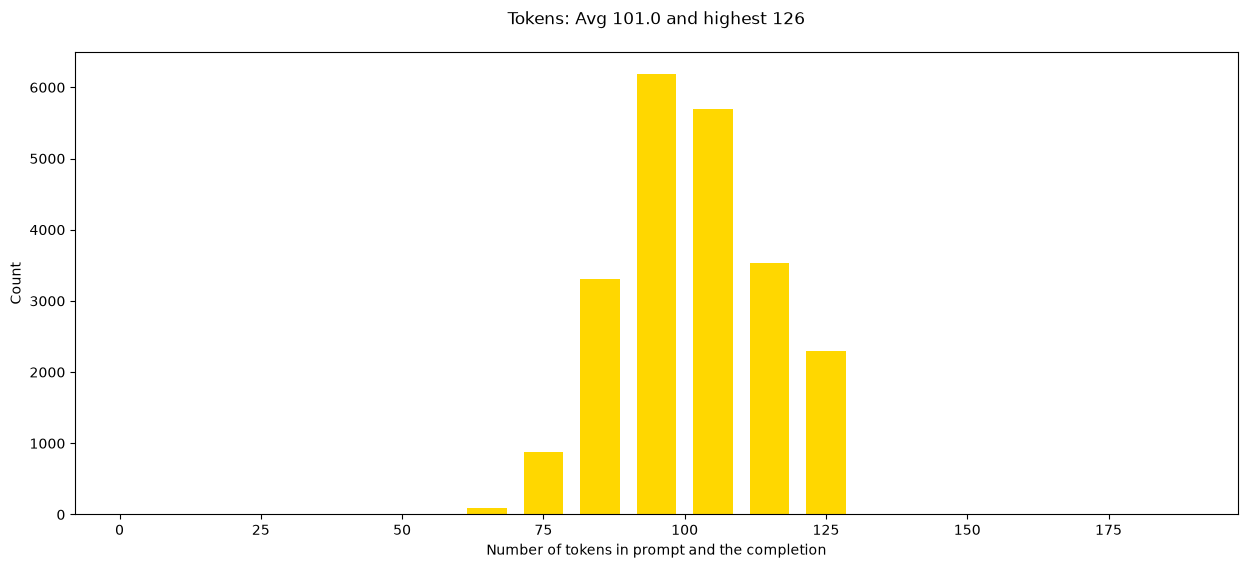

In [29]:
plt.figure(figsize=(15, 6))
plt.title(f"Tokens: Avg {sum(prompt_token_counts)/len(prompt_token_counts):,.1f} and highest {max(prompt_token_counts)}\n")
plt.xlabel("Number of tokens in prompt and the completion")
plt.ylabel("Count")
plt.hist(prompt_token_counts, rwidth=0.7, color='gold', bins=range(0, 200, 10))
plt.show()

In [30]:
username1 = "irene12"
dataset_name = f"{username1}/items_prompts_lite" if LITE_MODE else f"{username1}/items_prompts_full"

print("Uploading to: ", dataset_name)
Item.push_prompts_to_hub(dataset_name, train, val, test)

Uploading to:  irene12/items_prompts_lite


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ?it/s]

Creating parquet from Arrow format:   0%|          | 0/20 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

...

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

README.md:   0%|          | 0.00/484 [00:00<?, ?B/s]

In [18]:
train[0]

<Schlage F59 AND 613 Andover Interior Knob with Deadbolt, Oil Rubbed Bronze (Interior Half Only) = $64.3>